In [1]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
# from scipy.stats import bootstrap
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate, KFold

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
# resultado = bootstrap(
#     data=(dados,),
#     statistic=np.mean,
#     n_resamples=10_000,
#     confidence_level=0.95,
#     method="percentile",
#     rng=np.random.default_rng(42))

Acurácia: 0.625

Matriz de confusão:
[[240  57  44]
 [ 93 145  90]
 [ 31  60 240]]

Relatório:
              precision    recall  f1-score   support

           1       0.66      0.70      0.68       341
           2       0.55      0.44      0.49       328
           3       0.64      0.73      0.68       331

    accuracy                           0.62      1000
   macro avg       0.62      0.62      0.62      1000
weighted avg       0.62      0.62      0.62      1000



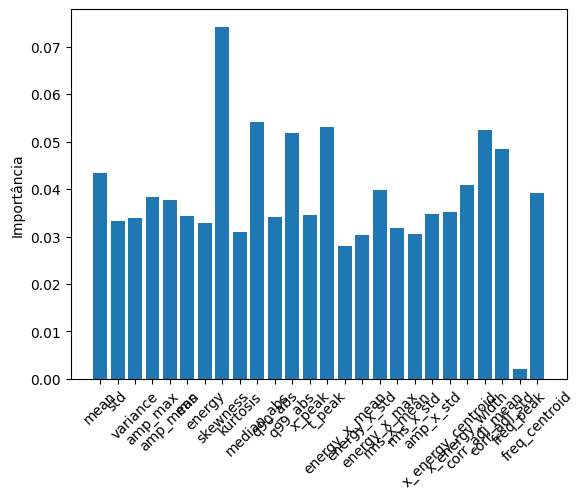

In [3]:
# df = pd.read_csv('databasev2.csv')
df = pd.read_csv('databasev3.csv')

# df = df[df['t_peak']>0.1e-9]

Y = df[["soil_type","radius","pos_y","pos_x"]]
X = df.drop(columns=["soil_type","radius","pos_y","pos_x"])

y = Y['soil_type']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

modelo = RandomForestClassifier(n_estimators=100, max_depth=None, random_state=42)

modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)

print("Acurácia:", accuracy_score(y_test,y_pred))

print("\nMatriz de confusão:")
print(confusion_matrix(y_test,y_pred))

print("\nRelatório:")
print(classification_report(y_test,y_pred))

nomes = ['mean', 'std', 'variance', 'amp_max', 'amp_mean', 'rms', 'energy',
       'skewness', 'kurtosis', 'median_abs', 'q90_abs', 'q99_abs', 'x_peak',
       't_peak', 'energy_x_mean', 'energy_x_std', 'energy_x_max', 'rms_x_mean',
       'rms_x_std', 'amp_x_std', 'x_energy_centroid', 'x_energy_width',
       'corr_adj_mean', 'corr_adj_std', 'freq_peak', 'freq_centroid']

imp = modelo.feature_importances_

plt.bar(nomes,imp)
plt.ylabel("Importância")
plt.xticks(rotation=45)
plt.show()

AINDA É POSSÍVEL MELHORAR APLICANDO FEATURE SELECTION

In [ ]:
y_posx = Y[X['t_peak']>0.1e-9]['pos_x']
X_posx = X[X['t_peak']>0.1e-9]

model = RandomForestRegressor(n_estimators=100,random_state=0,n_jobs=4)
cv = KFold(n_splits=10,shuffle=True,random_state=42)

results = cross_validate(model,X_posx,y_posx,cv=cv,scoring={'R2':'r2',
                                                  'MAE':'neg_mean_absolute_error',
                                                  'RMSE':'neg_root_mean_squared_error',
                                                  'MSE':'neg_mean_squared_error'})

print(results['test_R2'].mean())
print(results['test_MAE'].mean())
print(results['test_RMSE'].mean())
print(results['test_MSE'].mean())

0.8722114178894991
-0.014244745263157893
-0.019671495106543917
-0.0003887477866371191


In [5]:
y = Y['pos_y']

model = RandomForestRegressor(n_estimators=100,random_state=0,n_jobs=4)
cv = KFold(n_splits=10,shuffle=True,random_state=42)

results = cross_validate(model,X,y,cv=cv,scoring={'R2':'r2',
                                                  'MAE':'neg_mean_absolute_error',
                                                  'RMSE':'neg_root_mean_squared_error',
                                                  'MSE':'neg_mean_squared_error'})

print(results['test_R2'].mean())
print(results['test_MAE'].mean())
print(results['test_RMSE'].mean())
print(results['test_MSE'].mean())

0.7127836922821807
-0.00631843684210526
-0.008115396478137044
-6.59207162049861e-05


In [6]:
y = Y['radius']

model = RandomForestRegressor(n_estimators=100,random_state=0,n_jobs=4)
cv = KFold(n_splits=10,shuffle=True,random_state=42)

results = cross_validate(model,X,y,cv=cv,scoring={'R2':'r2',
                                                  'MAE':'neg_mean_absolute_error',
                                                  'RMSE':'neg_root_mean_squared_error',
                                                  'MSE':'neg_mean_squared_error'})

print(results['test_R2'].mean())
print(results['test_MAE'].mean())
print(results['test_RMSE'].mean())
print(results['test_MSE'].mean())

0.18718683196860378
-0.003211625052631578
-0.003838042436412407
-1.4743900405761763e-05
